# 1. PROJECT TITLE & OVERVIEW

# Student Performance: Statistical Analysis

## Project Overview

This project investigates factors associated with students' final academic performance using the Student Performance Dataset. (https://www.kaggle.com/datasets/larsen0966/student-performance-data-set/data)

The analysis focuses on descriptive statistics, group comparisons, correlation analysis, and non-parametric hypothesis testing to examine relationships between student characteristics, academic history, and final grade.

### Objectives

- Explore the distribution of students' final grades.
- Compare final grades across selected student groups.
- Examine whether previous academic failures are associated with final grades.
- Investigate the relationship between school absences and final grades.
- Apply appropriate statistical tests and effect-size measures.

## Research Questions

1. Does final grade differ significantly by sex?
2. Is study time associated with final grade?
3. Does the number of previous failures relate significantly to final grade?
4. Is there a significant relationship between school absences and final grade?

# 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import (
    shapiro,
    mannwhitneyu,
    kruskal,
    spearmanr,
    pearsonr
)

# 3. Load the Dataset

In [2]:
df = pd.read_csv("student-por.csv")

In [3]:
df

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
644,MS,F,19,R,GT3,T,2,3,services,other,...,5,4,2,1,2,5,4,10,11,10
645,MS,F,18,U,LE3,T,3,1,teacher,services,...,4,3,4,1,1,1,4,15,15,16
646,MS,F,18,U,GT3,T,1,1,other,other,...,1,1,1,1,1,5,6,11,12,9
647,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,6,10,10,10


In [4]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [5]:
# check the dimension
df.shape

(649, 33)

# 4. Data Audit
This section demonstrates that you checked the quality of the data before performing statistical analysis.

In [6]:
# check column names
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')

In [7]:
# easier to read
list(df.columns)

['school',
 'sex',
 'age',
 'address',
 'famsize',
 'Pstatus',
 'Medu',
 'Fedu',
 'Mjob',
 'Fjob',
 'reason',
 'guardian',
 'traveltime',
 'studytime',
 'failures',
 'schoolsup',
 'famsup',
 'paid',
 'activities',
 'nursery',
 'higher',
 'internet',
 'romantic',
 'famrel',
 'freetime',
 'goout',
 'Dalc',
 'Walc',
 'health',
 'absences',
 'G1',
 'G2',
 'G3']

In [8]:
# Basic information about the data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

In [9]:
# Check missing value
df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [10]:
df.isnull().mean() * 100

school        0.0
sex           0.0
age           0.0
address       0.0
famsize       0.0
Pstatus       0.0
Medu          0.0
Fedu          0.0
Mjob          0.0
Fjob          0.0
reason        0.0
guardian      0.0
traveltime    0.0
studytime     0.0
failures      0.0
schoolsup     0.0
famsup        0.0
paid          0.0
activities    0.0
nursery       0.0
higher        0.0
internet      0.0
romantic      0.0
famrel        0.0
freetime      0.0
goout         0.0
Dalc          0.0
Walc          0.0
health        0.0
absences      0.0
G1            0.0
G2            0.0
G3            0.0
dtype: float64

In [11]:
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing %": df.isnull().mean() * 100
})

missing

,Missing Values,Missing %
school,0,0.0
sex,0,0.0
age,0,0.0
address,0,0.0
famsize,0,0.0
Pstatus,0,0.0
Medu,0,0.0
Fedu,0,0.0
Mjob,0,0.0
Fjob,0,0.0


In [12]:
# Check DUPLICATES
df.duplicated().sum()

np.int64(0)

In [13]:
df[df.duplicated()]

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3


In [14]:
# Statistical Summary
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


In [15]:
# check categoriclal Vairable
df.describe(include="object")

,school,sex,address,famsize,Pstatus,Mjob,Fjob,reason,guardian,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
count,649,649,649,649,649,649,649,649,649,649,649,649,649,649,649,649,649
unique,2,2,2,2,2,5,5,4,3,2,2,2,2,2,2,2,2
top,GP,F,U,GT3,T,other,other,course,mother,no,yes,no,no,yes,yes,yes,no
freq,423,383,452,457,569,258,367,285,455,581,398,610,334,521,580,498,410


In [16]:
df["sex"].value_counts()

sex
F    383
M    266
Name: count, dtype: int64

In [17]:
# let's inspect gender. we can do the same for other categorical vairables
df["sex"].unique()

array(['F', 'M'], dtype=object)

In [18]:
df["sex"].nunique()

2

In [19]:
df["sex"].value_counts(normalize=True) * 100

sex
F    59.013867
M    40.986133
Name: proportion, dtype: float64

In [20]:
# Every column's unique values count:
df.nunique().sort_values()

school         2
sex            2
address        2
famsize        2
Pstatus        2
schoolsup      2
paid           2
famsup         2
nursery        2
romantic       2
internet       2
higher         2
activities     2
guardian       3
studytime      4
traveltime     4
failures       4
reason         4
freetime       5
Mjob           5
Medu           5
Fjob           5
Fedu           5
famrel         5
health         5
goout          5
Dalc           5
Walc           5
age            8
G2            16
G1            17
G3            17
absences      24
dtype: int64

In [21]:
#check Data type
df.dtypes

school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object

In [22]:
#Table  of what we did above:

audit = pd.DataFrame({
    "Data Type": df.dtypes,
    "Non-Null Count": df.notnull().sum(),
    "Missing Values": df.isnull().sum(),
    "Missing %": df.isnull().mean() * 100,
    "Unique Values": df.nunique()
})

audit

,Data Type,Non-Null Count,Missing Values,Missing %,Unique Values
school,object,649,0,0.0,2
sex,object,649,0,0.0,2
age,int64,649,0,0.0,8
address,object,649,0,0.0,2
famsize,object,649,0,0.0,2
Pstatus,object,649,0,0.0,2
Medu,int64,649,0,0.0,5
Fedu,int64,649,0,0.0,5
Mjob,object,649,0,0.0,5
Fjob,object,649,0,0.0,5


# 5. Understand the main variables

Step 2: Understand the Variables
2.1 Before calculating statistics, we need to know what each variable represents and what type of variable it is.
Student characteristics: school
sex
age
address
famsize
Pstatus
Family & parental background:
Medu
Fedu
Mjob
Fjob
reason
guardian
Academic / school-related factors:
traveltime
studytime
failures
schoolsup
famsup
paid
activities
nursery
higher
internet
Social & lifestyle factors:
romantic
famrel
freetime
goout
Dalc
Walc
health
absences
Academic performance:
G1,  G2,   G3

2.2 Separate numerical and categorical variables
We can initially let Pandas identify them:

In [23]:
numerical_cols = df.select_dtypes(include="number").columns
categorical_cols = df.select_dtypes(include="object").columns

print("Numerical variables:")
print(list(numerical_cols))


Numerical variables:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [24]:

print("\nCategorical variables:")
print(list(categorical_cols))


Categorical variables:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


2.3 Descriptive statistics for continuous variables
Note: some of the numerical variables are are ordinal variable not continuous

for cont variable, We want to understand:
Central tendency → mean and median
Variability → standard deviation and IQR
Range → minimum and maximum
Potential outliers/skewness

In [25]:
df[["age", "absences", "G1", "G2", "G3"]].describe()

,age,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,3.659476,11.399076,11.570108,11.906009
std,1.218138,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,32.000000,19.000000,19.000000,19.000000


2.4 Calculating descriptive statististics manually/ourselves

In [26]:
print("Mean:", df["G3"].mean())
print("Median:", df["G3"].median())
print("Standard Deviation:", df["G3"].std())
print("Minimum:", df["G3"].min())
print("Maximum:", df["G3"].max())


print("Q1:", df["G3"].quantile(0.25))
print("Q3:", df["G3"].quantile(0.75))


IQR = df["G3"].quantile(0.75) - df["G3"].quantile(0.25)
print("IQR:", IQR)

Mean: 11.906009244992296
Median: 12.0
Standard Deviation: 3.2306562428048045
Minimum: 0
Maximum: 19
Q1: 10.0
Q3: 14.0
IQR: 4.0


2.5 Create a clean descriptive-statistics table

In [27]:
desc_stats = pd.DataFrame({
    "Mean": df[["age", "absences", "G1", "G2", "G3"]].mean(),
    "Median": df[["age", "absences", "G1", "G2", "G3"]].median(),
    "Std Dev": df[["age", "absences", "G1", "G2", "G3"]].std(),
    "Min": df[["age", "absences", "G1", "G2", "G3"]].min(),
    "Q1": df[["age", "absences", "G1", "G2", "G3"]].quantile(0.25),
    "Q3": df[["age", "absences", "G1", "G2", "G3"]].quantile(0.75),
    "Max": df[["age", "absences", "G1", "G2", "G3"]].max()
})

desc_stats

,Mean,Median,Std Dev,Min,Q1,Q3,Max
age,16.744222,17.0,1.218138,15,16.0,18.0,22
absences,3.659476,2.0,4.640759,0,0.0,6.0,32
G1,11.399076,11.0,2.745265,0,10.0,13.0,19
G2,11.570108,11.0,2.913639,0,10.0,13.0,19
G3,11.906009,12.0,3.230656,0,10.0,14.0,19


2.6 Frequency analysis for categorical variables
For categorical variables, mean and standard deviation aren't appropriate.
Instead, we look at frequencies and percentages.

In [28]:
df["sex"].value_counts()

sex
F    383
M    266
Name: count, dtype: int64

In [29]:
df["sex"].value_counts(normalize=True) * 100

sex
F    59.013867
M    40.986133
Name: proportion, dtype: float64

In [30]:
def frequency_table(data, column):
    table = data[column].value_counts().to_frame("Frequency")
    table["Percentage"] = data[column].value_counts(normalize=True) * 100
    return table

In [31]:
frequency_table(df, "sex")

,Frequency,Percentage
sex,,
F,383,59.013867
M,266,40.986133


In [32]:
frequency_table(df, "school")

,Frequency,Percentage
school,,
GP,423,65.177196
MS,226,34.822804


In [33]:

frequency_table(df, "address")


,Frequency,Percentage
address,,
U,452,69.645609
R,197,30.354391


In [34]:
frequency_table(df, "famsize")

,Frequency,Percentage
famsize,,
GT3,457,70.416025
LE3,192,29.583975


In [35]:
frequency_table(df, "Mjob")

,Frequency,Percentage
Mjob,,
other,258,39.753467
services,136,20.955316
at_home,135,20.801233
teacher,72,11.093991
health,48,7.395994


In [36]:
frequency_table(df, "Fjob")

,Frequency,Percentage
Fjob,,
other,367,56.548536
services,181,27.889060
at_home,42,6.471495
teacher,36,5.546995
health,23,3.543914


2.7 Frequency analysis for ordinal variable "studytime"
background information:
studytime - weekly study time (numeric: 1 - <2 hours, 2 - 2 to 5 hours, 3 - 5 to 10 hours, or 4 - >10 hours) 

In [37]:
#how many students fall into each 'studytime' category
frequency_table(df, "studytime")

,Frequency,Percentage
studytime,,
2,305,46.995378
1,212,32.665639
3,97,14.946071
4,35,5.392912


2.8 Analyze our main outcome variable: G3

In [38]:
df["G3"].describe()

count    649.000000
mean      11.906009
std        3.230656
min        0.000000
25%       10.000000
50%       12.000000
75%       14.000000
max       19.000000
Name: G3, dtype: float64

In [39]:
df["G3"].value_counts().sort_index()

G3
0      15
1       1
5       1
6       3
7      10
8      35
9      35
10     97
11    104
12     72
13     82
14     63
15     49
16     36
17     29
18     15
19      2
Name: count, dtype: int64

In [40]:
df["G3"].value_counts(normalize=True).sort_index() * 100


G3
0      2.311248
1      0.154083
5      0.154083
6      0.462250
7      1.540832
8      5.392912
9      5.392912
10    14.946071
11    16.024653
12    11.093991
13    12.634823
14     9.707242
15     7.550077
16     5.546995
17     4.468413
18     2.311248
19     0.308166
Name: proportion, dtype: float64

2.9 Create a pass/fail variable
The Portuguese grading system uses 10/20 as the usual passing threshold.

In [41]:
df["pass"] = (df["G3"] >= 10).astype(int)

In [42]:
df["pass"].value_counts()

pass
1    549
0    100
Name: count, dtype: int64

In [43]:
#readable version
df["performance"] = df["G3"].apply(
    lambda x: "Pass" if x >= 10 else "Fail"
)

In [44]:
frequency_table(df, "performance")

,Frequency,Percentage
performance,,
Pass,549,84.59168
Fail,100,15.40832


In [45]:
""" Important

We're not deleting or replacing G3. We're creating a derived variable.

G3 remains our continuous grade variable, while performance can be used for categorical analyses such as chi-square tests."""

" Important\n\nWe're not deleting or replacing G3. We're creating a derived variable.\n\nG3 remains our continuous grade variable, while performance can be used for categorical analyses such as chi-square tests."

Overall, the dataset contains 649 secondary-school students with a mean age of 16.74 years. Final academic performance was moderate, with a mean G3 grade of 11.91 out of 20 and a median of 12. Grades showed meaningful variation, ranging from 0 to 19. Most students passed the course, with 84.6% achieving a final grade of at least 10. Absences were positively skewed, with a median of 2 but a mean of 3.66 and a maximum of 32. Female students represented 59.0% of the sample, while the most common study-time category was 2–5 hours per week. Most students had no previous class failures (84.6%), and only 10.5% reported receiving additional school educational support. These descriptive findings suggest several potentially important factors for further investigation, particularly study time, previous failures, absenteeism, gender, and educational support.

# 6. Exploratory Data Analysis

STEP 3 EDA

# 6.1 Distribution of Final Grade

3A - Distribution of Final Grade

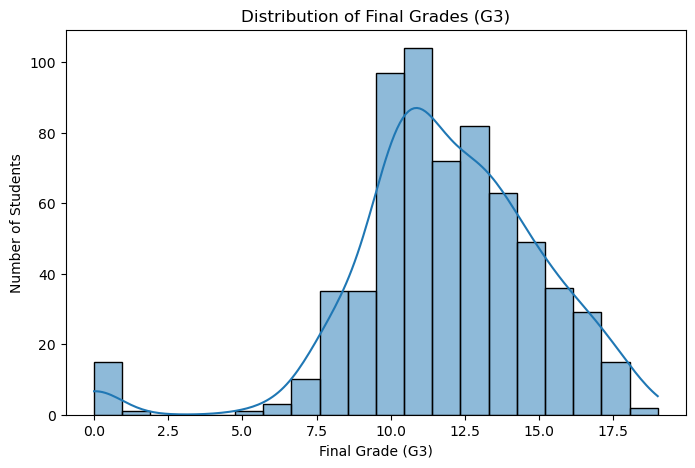

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(df["G3"], bins=20, kde=True)

plt.title("Distribution of Final Grades (G3)")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.show()

#it's left skewed

Step 3B — Boxplot of G3

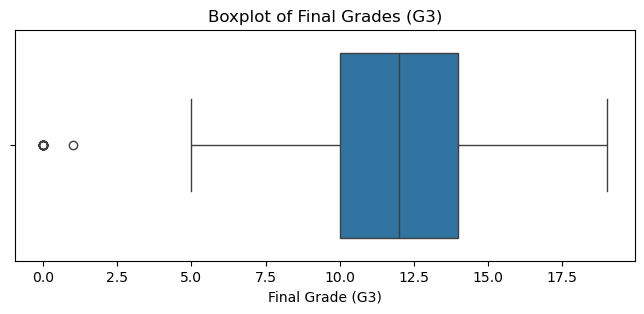

In [47]:
plt.figure(figsize=(8, 3))

sns.boxplot(x=df["G3"])

plt.title("Boxplot of Final Grades (G3)")
plt.xlabel("Final Grade (G3)")
plt.show()

# 6.2. Distribution of Absences

Step 3C — Distribution of Absences

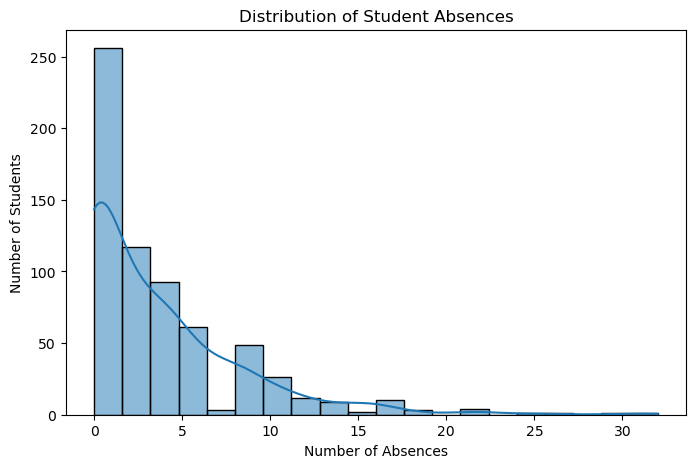

In [48]:
plt.figure(figsize=(8, 5))

sns.histplot(df["absences"], bins=20, kde=True)

plt.title("Distribution of Student Absences")
plt.xlabel("Number of Absences")
plt.ylabel("Number of Students")
plt.show()

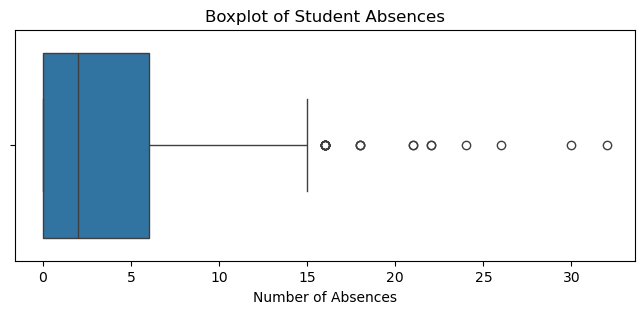

In [49]:
plt.figure(figsize=(8, 3))

sns.boxplot(x=df["absences"])

plt.title("Boxplot of Student Absences")
plt.xlabel("Number of Absences")
plt.show()

# 6.3. Distribution of Grades

Step 3D — G1, G2 and G3

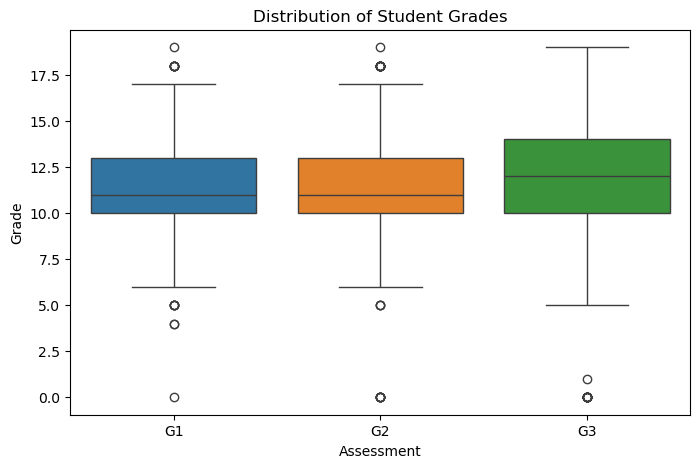

In [50]:
grades = df[["G1", "G2", "G3"]]

plt.figure(figsize=(8, 5))

sns.boxplot(data=grades)

plt.title("Distribution of Student Grades")
plt.xlabel("Assessment")
plt.ylabel("Grade")
plt.show()

# 6.4. Final Grade by Sex

Step 3E — G3 by Gender
Now we start looking at potential explanatory variables.

In [51]:
df.groupby("sex")["G3"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
sex,,,,,,
F,383,12.253264,12.0,3.124147,0,19
M,266,11.406015,11.0,3.320690,0,19


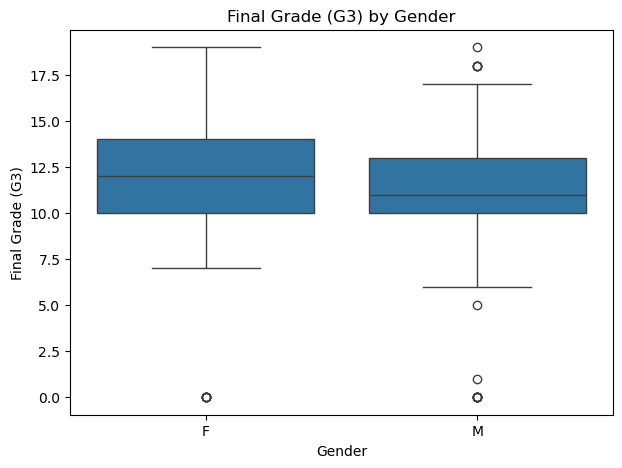

In [52]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x="sex", y="G3")

plt.title("Final Grade (G3) by Gender")
plt.xlabel("Gender")
plt.ylabel("Final Grade (G3)")
plt.show()

# 6.5. Final Grade by Study Time

Step 3F — G3 by Study Time

In [53]:
df.groupby("studytime")["G3"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
studytime,,,,,,
1,212,10.844340,11.0,3.218624,0,18
2,305,12.091803,12.0,3.243125,0,19
3,97,13.226804,13.0,2.502104,8,18
4,35,13.057143,13.0,3.038410,6,19


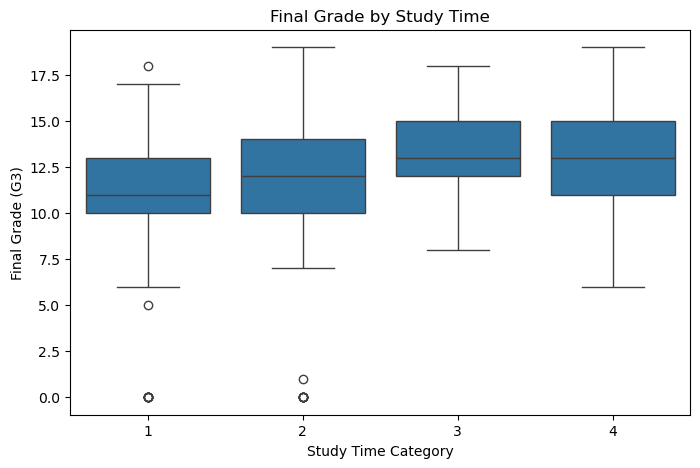

In [54]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="studytime", y="G3")

plt.title("Final Grade by Study Time")
plt.xlabel("Study Time Category")
plt.ylabel("Final Grade (G3)")
plt.show()

# 6.6. Final Grade by Previous Failures

Step 3G — G3 by Previous Failures
Look at whether students with more previous failures tend to have lower final grades.

In [55]:
df.groupby("failures")["G3"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
failures,,,,,,
0,549,12.510018,12.0,2.828813,0,19
1,70,8.642857,10.0,3.443270,0,16
2,16,8.812500,9.5,3.208712,0,15
3,14,8.071429,8.5,2.786348,0,11


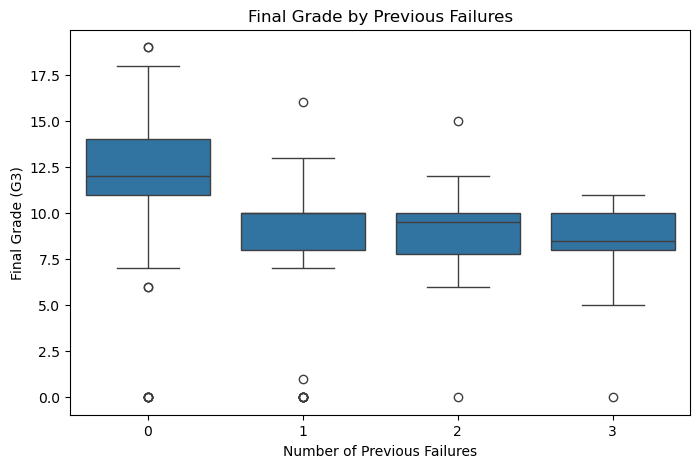

In [56]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="failures", y="G3")

plt.title("Final Grade by Previous Failures")
plt.xlabel("Number of Previous Failures")
plt.ylabel("Final Grade (G3)")
plt.show()

# 6.7. Absences vs Final Grade

Step 3H — Absences vs Final Grade
Now let's examine our continuous relationship:

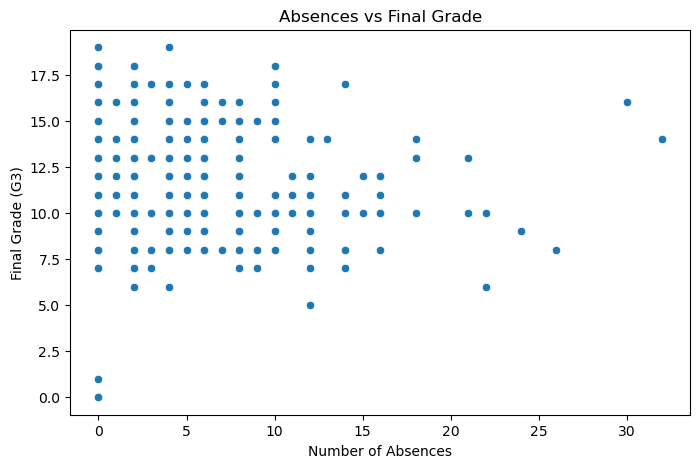

In [57]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="absences", y="G3")

plt.title("Absences vs Final Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (G3)")
plt.show()

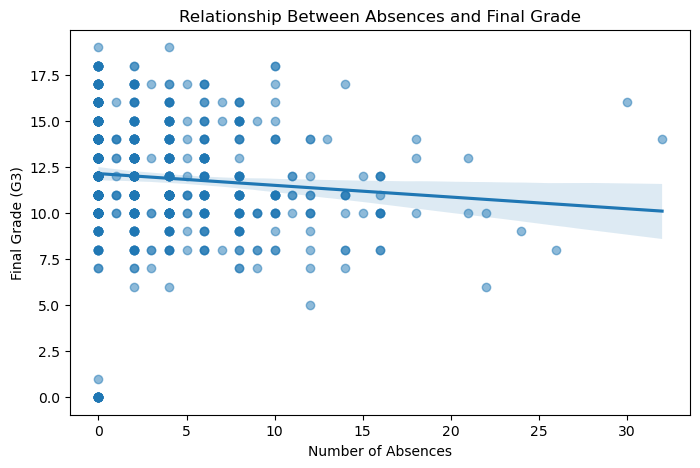

In [58]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=df,
    x="absences",
    y="G3",
    scatter_kws={"alpha": 0.5}
)

plt.title("Relationship Between Absences and Final Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (G3)")
plt.show()

#there doesn't seeem to be a clear relationship

Step 3I — Correlation Matrix
Finally, let's get an initial look at relationships among our numerical variables.

In [59]:
corr = df[
    ["age", "absences", "G1", "G2", "G3"]
].corr()

corr

,age,absences,G1,G2,G3
age,1.000000,0.149998,-0.174322,-0.107119,-0.106505
absences,0.149998,1.000000,-0.147149,-0.124745,-0.091379
G1,-0.174322,-0.147149,1.000000,0.864982,0.826387
G2,-0.107119,-0.124745,0.864982,1.000000,0.918548
G3,-0.106505,-0.091379,0.826387,0.918548,1.000000


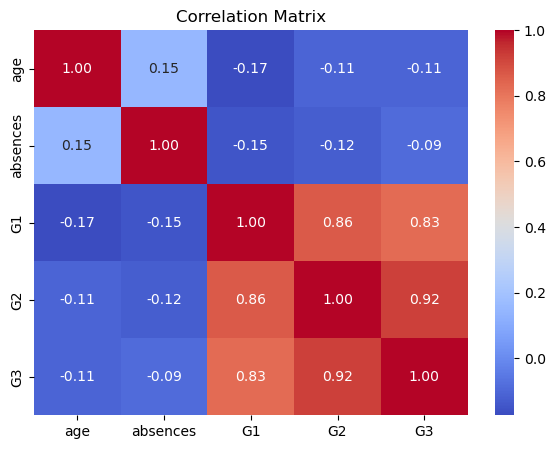

In [60]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()

In [61]:
df[["absences", "G3"]].corr(method="spearman")

,absences,G3
absences,1.00000,-0.15851
G3,-0.15851,1.00000


In [62]:
df[["absences", "G3"]].corr(method="pearson")

,absences,G3
absences,1.000000,-0.091379
G3,-0.091379,1.000000


In [63]:
from scipy.stats import spearmanr, pearsonr

spearman_corr, spearman_p = spearmanr(df["absences"], df["G3"])
pearson_corr, pearson_p = pearsonr(df["absences"], df["G3"])

print("Spearman correlation:", spearman_corr)
print("Spearman p-value:", spearman_p)

print("Pearson correlation:", pearson_corr)
print("Pearson p-value:", pearson_p)

Spearman correlation: -0.15851002809372583
Spearman p-value: 4.991938518202622e-05
Pearson correlation: -0.09137905643875618
Pearson p-value: 0.0198956239391607


In [64]:
""" 
A Spearman correlation revealed a weak but statistically significant negative association between absences and final grade (ρ = -0.159, p < 0.001). 
This suggests that students with higher absence counts tended to achieve slightly lower final grades. However, 
the weak correlation indicates that absences alone are not a strong predictor of academic performance.
"""


' \nA Spearman correlation revealed a weak but statistically significant negative association between absences and final grade (ρ = -0.159, p < 0.001). \nThis suggests that students with higher absence counts tended to achieve slightly lower final grades. However, \nthe weak correlation indicates that absences alone are not a strong predictor of academic performance.\n'

# 7. Research Question 1

the EDA shows the result what we have 'observed' but it's not statistically proven yet for that we will do the hyp[othesis testing.

STEP 4  Hypothesis Testing

Research Question 1
Do final grades differ significantly between male and female students?


In [65]:
#Test for normalitty assumption before applying a t-test.

#H₀: G3 is normally distributed within the group.
#H₁: G3 is not normally distributed within the group.
from scipy.stats import shapiro

female = df.loc[df["sex"] == "F", "G3"]
male = df.loc[df["sex"] == "M", "G3"]

print("Female Shapiro-Wilk:")
print(shapiro(female))

print("\nMale Shapiro-Wilk:")
print(shapiro(male))

#Since both p-values are far below 0.05, we reject H₀.
#other valid cases: 
#G3 is a discrete grade variable,
#the distributions are clearly not perfectly normal, and we're already taking a non-parametric approach for some of our other variables,

Female Shapiro-Wilk:
ShapiroResult(statistic=np.float64(0.9341671479652868), pvalue=np.float64(5.699868579725032e-12))

Male Shapiro-Wilk:
ShapiroResult(statistic=np.float64(0.9128728221238557), pvalue=np.float64(2.5360429344278745e-11))


In [66]:
#H₀: The distribution of final grades is the same for male and female students.
#H₁: The distribution of final grades differs between male and female students.
#Use α = 0.05.
from scipy.stats import mannwhitneyu

female = df.loc[df["sex"] == "F", "G3"]
male = df.loc[df["sex"] == "M", "G3"]

u_stat, p_value = mannwhitneyu(
    female,
    male,
    alternative="two-sided"
)

print("Mann-Whitney U statistic:", u_stat)
print("p-value:", p_value)

#interpretation:Because the p-value is below 0.05, there is statistically significant evidence of a difference in G3 between the two gender groups.
#So females in this sample had higher final grades on average and in median.

Mann-Whitney U statistic: 58916.5
p-value: 0.0006316613877703309


In [67]:
#even if there is an evidence of a difference, how large is the difference? is the effect size is large or small?

In [68]:
n_female = len(female)
n_male = len(male)

rank_biserial = (2 * u_stat) / (n_female * n_male) - 1

print("Rank-biserial correlation:", rank_biserial)

Rank-biserial correlation: 0.1566088851371248


The rank-biserial correlation of 0.157 indicates that the effect is small. In other words, although the difference is statistically significant, the magnitude of the difference between the groups is relatively modest.

In [69]:
""" A Mann–Whitney U test was conducted to examine whether final grades differed between female and male students. 
The analysis found a statistically significant difference in final grades between the two groups (U = 58,916.5, p < 0.001). 
    Female students had a higher mean final grade than male students (12.25 vs. 11.41), representing an average difference of approximately 0.85 points/marks 
on the 0–20 grading scale. The rank-biserial correlation was 0.157, indicating a small effect size. 
Thus, while gender was statistically associated with final grade in this sample, the magnitude of the observed difference was relatively small. """


' A Mann–Whitney U test was conducted to examine whether final grades differed between female and male students. \nThe analysis found a statistically significant difference in final grades between the two groups (U = 58,916.5, p < 0.001). \n    Female students had a higher mean final grade than male students (12.25 vs. 11.41), representing an average difference of approximately 0.85 points/marks \non the 0–20 grading scale. The rank-biserial correlation was 0.157, indicating a small effect size. \nThus, while gender was statistically associated with final grade in this sample, the magnitude of the observed difference was relatively small. '

# 8. Research Question 2

Research Question 2
Does study time significantly affect/differ with final grade? or Does final grade differ significantly across study-time groups?
(Literal meaning: the amount of time (indep var) students spend studying actually makes a real difference in their final grades (dependent var).)
Independent variable: studytime
Dependent variable: G3 (final grade)

In [70]:
#lets make the table again like we did above.

df.groupby("studytime")["G3"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
studytime,,,,,,
1,212,10.844340,11.0,3.218624,0,18
2,305,12.091803,12.0,3.243125,0,19
3,97,13.226804,13.0,2.502104,8,18
4,35,13.057143,13.0,3.038410,6,19


We can see that the group means are different, but descriptive differences alone don't tell us whether the differences are statistically significant.

State the Hypothesis
H₀: The mean final grade is the same across all study-time groups.
H₁: At least one study-time group has a different mean final grade.
H0: μ1 =μ2=μ3=μ4
H1:At least one μi differs

one-way ANOVA tests whether the group means differ significantly.
But before choosing ANOVA, we should check its assumptions:
Independence — observations should be independent.
Normality — G3 should be approximately normally distributed within groups.
Homogeneity of variances — the variances should be reasonably similar across groups.

since G3 is not normally disturbuted. we shouldn't automatically jump to ANOVA.
For this project, a good approach is:Kruskal–Wallis test.

Because G3 is a discrete grade variable and the study-time groups are quite unequal in size, Kruskal–Wallis is a reasonable non-parametric alternative if the ANOVA assumptions aren't adequately met.


H₀: The distribution of final grades is the same across the four study-time groups.
H₁: At least one study-time group's distribution of final grades differs from the others.

In [71]:
from scipy.stats import kruskal

result = kruskal(
    df[df['studytime'] == 1]['G3'],
    df[df['studytime'] == 2]['G3'],
    df[df['studytime'] == 3]['G3'],
    df[df['studytime'] == 4]['G3']
)

print(result)


KruskalResult(statistic=np.float64(50.31620817945674), pvalue=np.float64(6.841570528918375e-11))


H statistic = 50.316
p-value = 6.84 × 10⁻¹¹
Significance level: α = 0.05
Descision: 6.84×10−11 < 0.05

Therefore Reject Ho.
There is statistically significant evidence that final grades differ across the study-time groups.

In [72]:
""" A Kruskal–Wallis H test found a statistically significant difference in final-grade distributions across the four study-time groups 
(H = 50.316, p < 0.001). 
Descriptively, median final grades increased from 11 for students studying less than 2 hours to 12 for those studying 2–5 hours 
and 13 for those studying 5 hours or more. """

' A Kruskal–Wallis H test found a statistically significant difference in final-grade distributions across the four study-time groups \n(H = 50.316, p < 0.001). \nDescriptively, median final grades increased from 11 for students studying less than 2 hours to 12 for those studying 2–5 hours \nand 13 for those studying 5 hours or more. '

# 9. Research Question 3

Research Question 3
Does the number of previous failures relate significantly to final grade?

In [73]:
df.groupby("failures")["G3"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
failures,,,,,,
0,549,12.510018,12.0,2.828813,0,19
1,70,8.642857,10.0,3.443270,0,16
2,16,8.812500,9.5,3.208712,0,15
3,14,8.071429,8.5,2.786348,0,11


it looks like students with no previous failures have noticeably higher final grades than students who have experienced one or more failures.

Independent variable: failures — number of past class failures
Dependent variable: G3 — final grade
Because failures has four ordered groups (0, 1, 2, 3) and G3 is not normally distributed, 
we should use a Kruskal–Wallis H test to test whether final grades differ significantly across the failure groups.

H₀: Final-grade G3 distributions are the same across the four previous-failure groups.
H₁: At least one failure group has a different final-grade distribution.

In [74]:
from scipy.stats import kruskal

groups = [
    df.loc[df['failures'] == 0, 'G3'],
    df.loc[df['failures'] == 1, 'G3'],
    df.loc[df['failures'] == 2, 'G3'],
    df.loc[df['failures'] == 3, 'G3']
]

kruskal_result = kruskal(*groups)

print("Kruskal-Wallis H statistic:", kruskal_result.statistic)
print("p-value:", kruskal_result.pvalue)

Kruskal-Wallis H statistic: 130.65909268304242
p-value: 3.8997335139424093e-28


p < 0.05, we reject H₀ and conclude that there is a statistically significant difference in final grades across previous-failure groups.


# 9. Research Question 4

Research Question 4
Is there a statistically significant relationship/association between absences and final grade?

we calculated the correlation earlier so we have:
Absences: number of school absences
G3: final grade
Spearman correlation: rₛ = -0.1585
p-value = 4.99 × 10⁻⁵

We can now formally interpret this as a Spearman correlation test.

Hypotheses
H₀: There is no significant relationship between absences and final grade.
H₁: There is a significant relationship between absences and final grade.

Since p = 0.0000499 < 0.05, we reject H₀.

Interpretation

There was a statistically significant negative relationship between absences and final grade (Spearman's rₛ = −0.159, p < 0.001). This indicates that students with more absences tended to have lower final grades. However, the correlation was weak, suggesting that absences alone had a limited relationship with final grade.

# 10. Overall Conclsuion:


This statistical analysis examined several factors associated with students' final grades. The analysis found statistically significant differences in final grades across sex and previous-failure groups. Study time also showed differences in final-grade outcomes across its categories. School absences demonstrated a statistically significant but weak negative association with final grade.

Overall, the findings indicate that students' academic history and study-related characteristics are associated with final academic performance. However, these statistical associations should not be interpreted as evidence of causation.

# 11. Limitations:

* **Observational data:** The analysis identifies associations between variables but cannot establish causal relationships. For example, a significant relationship between absences and final grades does not mean that absences directly cause lower grades.

* **Dataset population:** The dataset represents a specific group of students and educational settings. Therefore, the findings may not generalize to students from different schools, regions, or educational systems.

* **Limited variables:** Final academic performance can be influenced by many factors. This analysis focuses on selected variables such as sex, study time, previous failures, and absences, while other potentially relevant factors may not have been included.

* **Unequal group sizes:** Some categories, particularly students with two or three previous failures, contain relatively few observations. This can make estimates for these groups less stable.

* **Statistical significance vs. practical importance:** A statistically significant result does not necessarily indicate a strong or practically important relationship. Effect sizes and the strength of associations were therefore considered alongside p-values.

* **Multiple comparisons:** Several research questions and statistical tests were examined. Consequently, some statistically significant findings should be interpreted with appropriate caution regarding the possibility of false-positive results.
